# Project 3 · Modeling and Evaluation
**Mapping Recycling Inequities: Predicting Waste Diversion Across NYC Communities**

| | |
|---|---|
| **Title** | DSC450_Project3_Modeling |
| **Author** | Hali Sarah Parsons (Data Scientist, Sprint 3) |
| **Date** | 2026-11-10 |
| **Modified By** | Claude (v2: added Section 4b, static + time-series ensemble and TFT, per instructor feedback) |
| **Description** | Trains and evaluates the models for RQ2 (what is associated with low recycling), RQ3 (which districts are high risk) and RQ4 (forecasting district recycling share), each against the baselines set in the EDA notebook. |

### Ground rules from the readings
- **Every model is compared with a baseline.** A model that can't beat "guess the average" or "repeat last year" adds nothing (Provost & Fawcett, 2013, Ch. 5 and Ch. 7).
- **Tuning happens inside the evaluation, never on the test data.** For the 59-district models that means *nested* cross-validation: an inner loop picks the settings, and an outer loop scores them on districts the inner loop never saw (Provost & Fawcett, 2013, Ch. 5). For the forecast, settings are picked on 2024 and the score comes from 2025–2026.
- **Small data, simple models.** With 59 districts, a flexible model can memorize noise. Simple models get the benefit of the doubt unless a complex one clearly wins.
- **Associations, not causes.** The regression says which district traits go together with low recycling. It can't say that changing a trait would change recycling (Stephens-Davidowitz, 2017, Ch. 7).

## 1. Setup
Run `DSC450_Project3_EDA_Feature_Engineering.ipynb` first in the same Colab session. It writes the `features/` folder this notebook reads. The forecast section also reads Matt's monthly file from `P3_Final_Data_Wrangling.zip`.

In [1]:
# WHY these libraries: scikit-learn for models and cross-validation, statsmodels for regression
# coefficients with confidence intervals, matplotlib for report-ready figures.
import os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.model_selection import RepeatedKFold, RepeatedStratifiedKFold, GridSearchCV, KFold, StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

if not os.path.isdir("P3_Final_Data_Wrangling") and os.path.exists("P3_Final_Data_Wrangling.zip"):
    with zipfile.ZipFile("P3_Final_Data_Wrangling.zip") as z:   # WHY: Colab starts empty each session
        z.extractall(".")
os.makedirs("figures", exist_ok=True); os.makedirs("model_results", exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)  # WHY: version notices only, they don't change results

SEED = 450  # WHY one seed: fold splits and forests come out the same every run
feat = pd.read_csv("features/district_features_2025.csv")
monthly = pd.read_csv("P3_Final_Data_Wrangling/outputs/dsny_monthly_complete_2005_2026_10_REBUILT.csv", parse_dates=["month"])
baselines = pd.read_csv("features/baselines.csv")

y = "recycling_share_2025_pct"
FEATURES = ["lep_pct", "rent_stab_share", "nycha_share", "permits_per_1k", "log_income"]
NICE = {"lep_pct": "Limited English proficiency", "rent_stab_share": "Rent-stabilized share",
        "nycha_share": "NYCHA share", "permits_per_1k": "New units per 1,000", "log_income": "Median income (log)"}
BORO_COLORS = {"Manhattan": "#2a78d6", "Bronx": "#eb6834", "Brooklyn": "#1baf7a", "Queens": "#eda100", "Staten Island": "#e87ba4"}
INK, MUTED, BLUE, ORANGE = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984",
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9})
assert len(feat) == 59 and feat[FEATURES + [y]].notna().all().all(), "feature table should be complete for 59 districts"
print(len(feat), "districts |", len(monthly), "monthly rows")

59 districts | 15458 monthly rows


## 2. RQ2 · Which community traits are associated with lower recycling share?
### 2a. Predictive check: do the traits explain the gaps better than guessing the average?
Five models, each scored with **5 × repeated 5-fold cross-validation** (25 train/test splits). Every district is predicted by a model that never saw it.
- **Mean baseline:** always guess the average of the training districts.
- **Income only:** linear regression on income alone. This tells us how much the other traits add *beyond* income.
- **All traits, linear:** linear regression on all five traits.
- **Ridge:** linear regression that shrinks coefficients, with the shrinkage picked by an inner cross-validation.
- **Random forest:** catches curves and interactions. Tree depth and leaf size are tuned in an inner loop (nested CV).

In [2]:
X, yv = feat[FEATURES].values, feat[y].values
outer = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def cv_regression(make_model, cols):
    '''Score a model with repeated 5-fold CV and return per-fold MAE, RMSE and R².

    WHY a factory: each fold gets a fresh, untrained model, so nothing learned in one fold leaks into another.'''
    Xc = feat[cols].values if cols else np.zeros((len(feat), 1))
    out = []
    for tr, te in outer.split(Xc):
        if make_model is None:                       # mean baseline
            pred = np.full(len(te), yv[tr].mean())
        else:
            mdl = make_model().fit(Xc[tr], yv[tr]); pred = mdl.predict(Xc[te])
        err = yv[te] - pred
        out.append({"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()),
                    "R2": 1 - (err ** 2).sum() / ((yv[te] - yv[tr].mean()) ** 2).sum()})
    return pd.DataFrame(out)

rf_grid = {"randomforestregressor__max_depth": [2, 4], "randomforestregressor__min_samples_leaf": [3, 6]}
models = {
    "Mean baseline": (None, None),
    "Income only (linear)": (lambda: LinearRegression(), ["log_income"]),
    "All traits (linear)": (lambda: make_pipeline(StandardScaler(), LinearRegression()), FEATURES),
    "All traits (ridge)": (lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))), FEATURES),
    # WHY GridSearchCV inside the outer loop: settings are chosen without seeing the outer test districts (nested CV).
    "All traits (random forest)": (lambda: GridSearchCV(make_pipeline(RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1)),
                                                        rf_grid, cv=KFold(3, shuffle=True, random_state=SEED),
                                                        scoring="neg_mean_absolute_error"), FEATURES),
}
rq2 = []
for name, (mk, cols) in models.items():
    r = cv_regression(mk, cols)
    rq2.append({"model": name, "MAE": r.MAE.mean(), "MAE_sd": r.MAE.std(), "RMSE": r.RMSE.mean(), "R2": r.R2.mean()})
rq2 = pd.DataFrame(rq2)
rq2["beats_baseline_by_pp"] = rq2.loc[0, "MAE"] - rq2["MAE"]
print(rq2.round(2).to_string(index=False))
rq2.to_csv("model_results/rq2_cv_results.csv", index=False)

                     model  MAE  MAE_sd  RMSE   R2  beats_baseline_by_pp
             Mean baseline 4.26    0.98  5.13 0.00                  0.00
      Income only (linear) 2.43    0.46  3.04 0.59                  1.84
       All traits (linear) 2.55    0.49  3.18 0.55                  1.71
        All traits (ridge) 2.57    0.48  3.20 0.54                  1.69
All traits (random forest) 2.71    0.53  3.42 0.47                  1.56


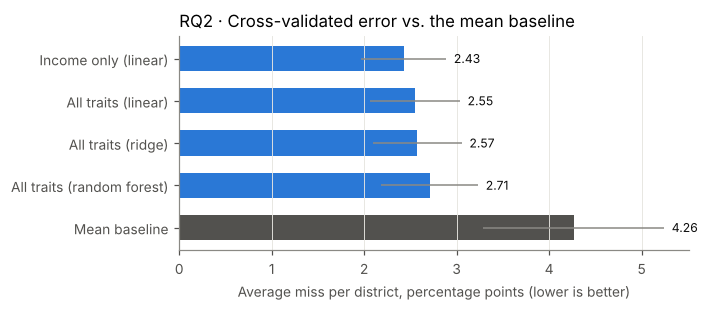

In [3]:
order = rq2.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 2.9))
colors = [MUTED if m == "Mean baseline" else BLUE for m in order.model]
ax.barh(order.model, order.MAE, xerr=order.MAE_sd, color=colors, height=0.6, error_kw={"ecolor": "#8a8984", "lw": 1})
for i, v in enumerate(order.MAE):
    ax.text(v + order.MAE_sd.iloc[i] + 0.08, i, f"{v:.2f}", va="center", fontsize=8, color=INK)
ax.set_xlabel("Average miss per district, percentage points (lower is better)"); ax.grid(axis="y", visible=False)
ax.set_title("RQ2 · Cross-validated error vs. the mean baseline", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig5_rq2_model_error.png", dpi=200); plt.show()

### 2b. Explanatory model: which traits matter once the others are held constant?
A linear regression on standardized traits, so each coefficient reads as "points of recycling share per one standard deviation of the trait, holding the others fixed." Standard errors use the HC3 correction, which stays reliable when the spread of errors differs across districts.

In [4]:
Z = (feat[FEATURES] - feat[FEATURES].mean()) / feat[FEATURES].std()
ols = sm.OLS(feat[y], sm.add_constant(Z)).fit(cov_type="HC3")
coef = pd.DataFrame({"coef": ols.params, "ci_low": ols.conf_int()[0], "ci_high": ols.conf_int()[1], "p": ols.pvalues}).drop("const")
coef["trait"] = coef.index.map(NICE)
print(f"R² = {ols.rsquared:.2f}, adjusted R² = {ols.rsquared_adj:.2f}, n = {int(ols.nobs)}")
print(coef[["trait", "coef", "ci_low", "ci_high", "p"]].round(3).to_string(index=False))
coef.to_csv("model_results/rq2_coefficients.csv")

# WHY these two checks: the income source and one top-coded district shouldn't decide the story.
Zf = Z.copy(); Zf["log_income"] = (feat.log_income_furman - feat.log_income_furman.mean()) / feat.log_income_furman.std()
ols_f = sm.OLS(feat[y], sm.add_constant(Zf)).fit(cov_type="HC3")
keep = feat.boro_cd != 101
ols_m = sm.OLS(feat.loc[keep, y], sm.add_constant(Z[keep])).fit(cov_type="HC3")
sens = pd.DataFrame({"ACS (main)": ols.params, "Furman income": ols_f.params, "Without Manhattan 1": ols_m.params}).drop("const")
sens.index = sens.index.map(NICE)
print("\nSensitivity, standardized coefficients:\n", sens.round(2).to_string())

R² = 0.68, adjusted R² = 0.65, n = 59
                      trait  coef  ci_low  ci_high     p
Limited English proficiency 0.605  -0.329    1.540 0.204
      Rent-stabilized share 0.228  -0.693    1.150 0.627
                NYCHA share 0.543  -0.541    1.628 0.326
        New units per 1,000 0.039  -0.819    0.896 0.930
        Median income (log) 4.843   3.661    6.026 0.000

Sensitivity, standardized coefficients:
                              ACS (main)  Furman income  Without Manhattan 1
Limited English proficiency        0.61           0.64                 0.61
Rent-stabilized share              0.23           0.08                 0.22
NYCHA share                        0.54           0.47                 0.54
New units per 1,000                0.04           0.23                 0.04
Median income (log)                4.84           4.84                 4.81


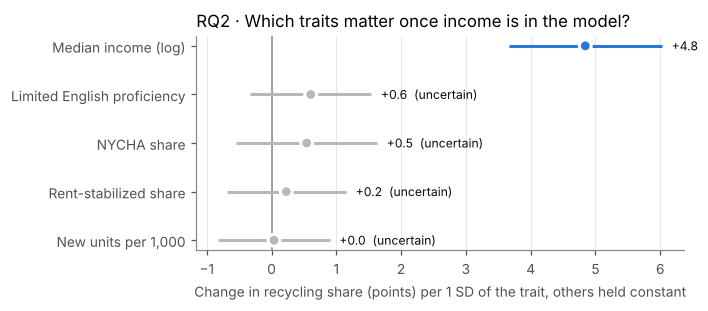

In [5]:
c = coef.sort_values("coef")
fig, ax = plt.subplots(figsize=(6.5, 2.9))
sig = (c.ci_low > 0) | (c.ci_high < 0)
ax.axvline(0, color="#8a8984", lw=1)
ax.hlines(range(len(c)), c.ci_low, c.ci_high, color=[BLUE if s else "#b9b8b2" for s in sig], lw=2)
ax.scatter(c.coef, range(len(c)), s=60, color=[BLUE if s else "#b9b8b2" for s in sig], edgecolor="white", linewidth=2, zorder=3)
ax.set_yticks(range(len(c)), c.trait); ax.grid(axis="y", visible=False)
for i, (v, s) in enumerate(zip(c.coef, sig)):
    ax.text(c.ci_high.iloc[i] + 0.15, i, f"{v:+.1f}" + ("" if s else "  (uncertain)"), va="center", fontsize=8, color=INK)
ax.set_xlabel("Change in recycling share (points) per 1 SD of the trait, others held constant")
ax.set_title("RQ2 · Which traits matter once income is in the model?", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig6_rq2_coefficients.png", dpi=200); plt.show()

In [6]:
# WHY permutation importance on the forest: a check, free of linear assumptions, on which traits the predictions lean on.
rf = RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=3, random_state=SEED, n_jobs=-1).fit(X, yv)
pi = permutation_importance(rf, X, yv, n_repeats=30, random_state=SEED, scoring="neg_mean_absolute_error")
imp = pd.Series(pi.importances_mean, index=[NICE[f] for f in FEATURES]).sort_values(ascending=False)
print("Random forest permutation importance (MAE increase in points when a trait is shuffled):\n", imp.round(2).to_string())

Random forest permutation importance (MAE increase in points when a trait is shuffled):
 Median income (log)            3.15
Limited English proficiency    0.24
New units per 1,000            0.22
NYCHA share                    0.08
Rent-stabilized share          0.04


### 2c. Which districts recycle less than their income predicts?
Income explains most of the gap, so the most useful outreach list may be the districts that fall **below what their income predicts**. Each district's expected share comes from the income-only model fit on the *other* 58 districts (leave-one-out), so no district grades itself. A large negative gap means something beyond income is holding that district back, such as building stock, collection setup or awareness. Those are the districts where outreach has the most room to help.

In [7]:
from sklearn.model_selection import LeaveOneOut, cross_val_predict
# WHY leave-one-out: each district's expected share comes from a model that never saw it.
feat["expected_share"] = cross_val_predict(LinearRegression(), feat[["log_income"]], feat[y], cv=LeaveOneOut())
feat["gap_vs_income"] = feat[y] - feat["expected_share"]
gap = feat[["boro_cd", "borough", y, "expected_share", "gap_vs_income", "hh_income"]].sort_values("gap_vs_income")
print("Furthest BELOW what income predicts:\n", gap.head(8).round(1).to_string(index=False))
print("\nFurthest ABOVE what income predicts:\n", gap.tail(5).round(1).to_string(index=False))
gap.to_csv("model_results/rq2_gap_vs_income.csv", index=False)

Furthest BELOW what income predicts:
  boro_cd   borough  recycling_share_2025_pct  expected_share  gap_vs_income  hh_income
     308  Brooklyn                       9.0            19.2          -10.3    92718.3
     110 Manhattan                       8.1            14.6           -6.5    57285.2
     202     Bronx                       5.1            11.1           -5.9    39093.0
     105 Manhattan                      19.8            25.5           -5.7   173062.9
     304  Brooklyn                      13.8            18.3           -4.5    85141.8
     311  Brooklyn                      12.2            16.4           -4.2    69789.7
     301  Brooklyn                      16.6            20.3           -3.7   104899.6
     316  Brooklyn                       8.6            12.2           -3.6    45008.1

Furthest ABOVE what income predicts:
  boro_cd  borough  recycling_share_2025_pct  expected_share  gap_vs_income  hh_income
     207    Bronx                      15.7           

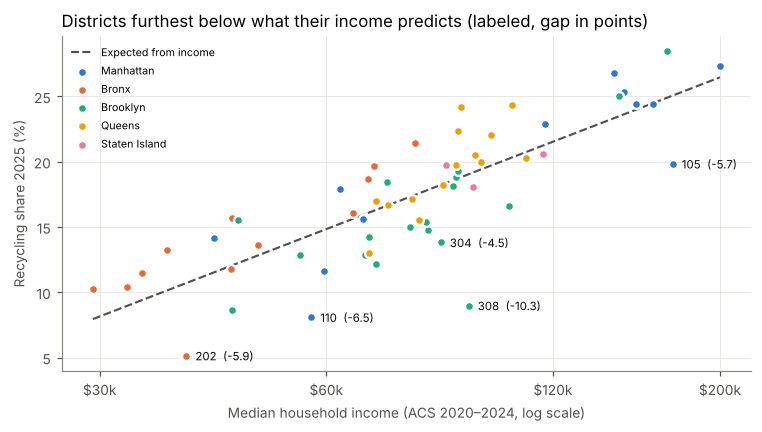

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
xs = np.linspace(feat.log_income.min(), feat.log_income.max(), 50)
line = LinearRegression().fit(feat[["log_income"]], feat[y])
ax.plot(np.exp(xs), line.predict(pd.DataFrame({"log_income": xs})), color=MUTED, lw=1.4, ls="--", label="Expected from income")
for b, col in BORO_COLORS.items():
    d = feat[feat.borough == b]
    ax.scatter(d.hh_income, d[y], s=34, color=col, edgecolor="white", linewidth=1.5, label=b, zorder=3)
for _, r in gap.head(5).iterrows():
    ax.annotate(f"{int(r.boro_cd)}  ({r.gap_vs_income:+.1f})", (r.hh_income, r[y]), xytext=(6, -3), textcoords="offset points", fontsize=7.5, color=INK)
ax.set_xscale("log"); ax.set_xticks([30000, 60000, 120000, 200000], ["$30k", "$60k", "$120k", "$200k"]); ax.minorticks_off()
ax.set_xlabel("Median household income (ACS 2020–2024, log scale)"); ax.set_ylabel("Recycling share 2025 (%)")
ax.legend(frameon=False, fontsize=7, loc="upper left")
ax.set_title("Districts furthest below what their income predicts (labeled, gap in points)", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig9_rq2_gap_vs_income.png", dpi=200); plt.show()

## 3. RQ3 · Can community traits flag the high-risk districts?
High risk = bottom quarter of 2025 share (15 districts). Since DSNY would act on a **short list**, the fair test is a ranking one (Provost & Fawcett, 2013, Ch. 8): each method ranks all 59 districts and we check how many of the true 15 land in its top 15 (**recall at 15**).

Methods compared:
- **Random:** expected recall at 15 is 25%.
- **Last year's list:** the 15 lowest districts in 2024. No model, just history.
- **Logistic regression** and **random forest** on the five community traits, with out-of-fold probabilities from repeated stratified 5-fold CV and settings tuned in an inner loop.

In [9]:
yr = feat["high_risk"].values
k = int(yr.sum())

def recall_at_k(scores):
    '''Share of truly high-risk districts that land in the top-k ranked by `scores` (higher = riskier).'''
    top = np.argsort(-scores)[:k]
    return yr[top].sum() / k

def oof_scores(make_model, reps=5):
    '''Average out-of-fold risk probability per district over repeated stratified 5-fold CV.

    WHY out-of-fold: each district is scored by a model that never saw it, so the ranking is honest.'''
    s, n = np.zeros(len(yr)), np.zeros(len(yr))
    for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=reps, random_state=SEED).split(X, yr):
        m = make_model().fit(X[tr], yr[tr]); s[te] += m.predict_proba(X[te])[:, 1]; n[te] += 1
    return s / n

logit = lambda: GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                             {"logisticregression__C": [0.03, 0.1, 0.3, 1, 3]},
                             cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
rfc = lambda: GridSearchCV(RandomForestClassifier(n_estimators=150, random_state=SEED, class_weight="balanced", n_jobs=-1),
                           {"max_depth": [2, 3], "min_samples_leaf": [2, 5]},
                           cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="roc_auc")
p_logit, p_rf = oof_scores(logit), oof_scores(rfc)
last_year = -feat["share_2024"].values           # WHY negative: lower share = riskier, and the ranking takes the highest

rq3 = pd.DataFrame([
    {"method": "Random", "recall_at_15": k / len(yr), "ROC_AUC": 0.5},
    {"method": "Last year's list", "recall_at_15": recall_at_k(last_year), "ROC_AUC": roc_auc_score(yr, last_year)},
    {"method": "Logistic regression (traits)", "recall_at_15": recall_at_k(p_logit), "ROC_AUC": roc_auc_score(yr, p_logit)},
    {"method": "Random forest (traits)", "recall_at_15": recall_at_k(p_rf), "ROC_AUC": roc_auc_score(yr, p_rf)},
])
print(rq3.round(2).to_string(index=False))
rq3.to_csv("model_results/rq3_results.csv", index=False)

scores = feat[["boro_cd", "borough", y, "high_risk", "share_2024"]].assign(risk_prob_logit=p_logit)
scores["rank_logit"] = scores.risk_prob_logit.rank(ascending=False).astype(int)
scores.sort_values("rank_logit").to_csv("model_results/rq3_district_risk_scores.csv", index=False)
# WHY list the disagreements: districts the traits call risky but history doesn't are the ones worth a closer look.
top_traits = set(scores.nsmallest(k, "rank_logit").boro_cd)
top_hist = set(feat.nsmallest(k, "share_2024").boro_cd)
print("\nTrait model flags, history doesn't:", sorted(top_traits - top_hist))
print("History flags, trait model doesn't:", sorted(top_hist - top_traits))

                      method  recall_at_15  ROC_AUC
                      Random          0.25     0.50
            Last year's list          0.93     1.00
Logistic regression (traits)          0.73     0.83
      Random forest (traits)          0.67     0.85

Trait model flags, history doesn't: [205, 207, 302, 313]
History flags, trait model doesn't: [110, 308, 311, 312]


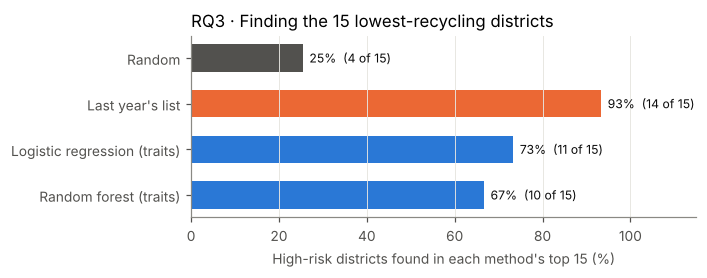

In [10]:
r = rq3.iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 2.6))
colors = [MUTED if m == "Random" else (ORANGE if m == "Last year's list" else BLUE) for m in r.method]
ax.barh(r.method, r.recall_at_15 * 100, color=colors, height=0.6)
for i, v in enumerate(r.recall_at_15 * 100):
    ax.text(v + 1.5, i, f"{v:.0f}%  ({round(v / 100 * k)} of {k})", va="center", fontsize=8, color=INK)
ax.set_xlim(0, 115); ax.set_xlabel("High-risk districts found in each method's top 15 (%)"); ax.grid(axis="y", visible=False)
ax.set_title("RQ3 · Finding the 15 lowest-recycling districts", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig7_rq3_recall.png", dpi=200); plt.show()

## 4. RQ4 · Forecasting each district's monthly share
Two horizons, because they allow different inputs:
- **1 month ahead:** last month's share is known, so `lag1` and a 3-month average are allowed.
- **12 months ahead (the RQ4 question):** only data from 12 or more months back is known, so the inputs are the same month last year (`lag12`), the month before that (`lag13`), two years back (`lag24`) and the average of months 12–23 back.

All lags are matched on the calendar date, not row position. Models: seasonal naive and persistence baselines, ridge regression, and gradient boosting (tuned on 2024, then refit on 2006–2024 and scored on January 2025 – October 2026).

In [11]:
ts = monthly[["month", "boro_cd", "borough", "recycling_share_pct"]].sort_values(["boro_cd", "month"]).reset_index(drop=True)
src = ts.set_index(["boro_cd", "month"])["recycling_share_pct"]

def lag(months):
    '''Share from exactly `months` calendar months earlier for every row, matched on date.

    WHY a date lookup: it can never pair the wrong months, even if a month were missing.'''
    keys = list(zip(ts.boro_cd, ts.month - pd.DateOffset(months=months)))
    return src.reindex(keys).values

for L in [1, 2, 3, 12, 13, 24] + list(range(14, 24)):
    ts[f"lag{L}"] = lag(L)
ts["roll3"] = ts[["lag1", "lag2", "lag3"]].mean(axis=1, skipna=False)
ts["yr_avg_12_23"] = ts[[f"lag{L}" for L in range(12, 24)]].mean(axis=1, skipna=False)
ts["month_num"] = ts.month.dt.month
ts["boro_code"] = ts.borough.astype("category").cat.codes
ts["split"] = np.select([ts.month < "2024-01-01", ts.month < "2025-01-01"], ["train", "valid"], "test")

H = {"1 month ahead": ["lag1", "roll3", "lag12", "month_num", "boro_code"],
     "12 months ahead": ["lag12", "lag13", "lag24", "yr_avg_12_23", "month_num", "boro_code"]}
data = ts.dropna(subset=sorted({c for v in H.values() for c in v}))
print("Rows by split (all lags available):", data.split.value_counts().reindex(["train", "valid", "test"]).to_dict(),
      "| first month:", data.month.min().date())

Rows by split (all lags available): {'train': 12036, 'valid': 708, 'test': 1298} | first month: 2007-01-01


In [12]:
def onehot(df, cols):
    '''Month and borough as indicator columns for ridge, which can't read category codes as categories.'''
    return pd.get_dummies(df[cols].astype({"month_num": "category", "boro_code": "category"}), drop_first=True).astype(float)

def mae(a, b): return float(np.abs(np.asarray(a) - np.asarray(b)).mean())
def rmse(a, b): return float(np.sqrt(((np.asarray(a) - np.asarray(b)) ** 2).mean()))

tr, va, te = (data[data.split == s] for s in ["train", "valid", "test"])
trva = pd.concat([tr, va])
rq4, preds = [], te[["month", "boro_cd", "borough", "recycling_share_pct", "lag12", "lag1"]].copy()
for h, cols in H.items():
    rows = [("Seasonal naive (same month last year)", te.lag12)]
    if h == "1 month ahead":
        rows.append(("Persistence (last month)", te.lag1))
    # Ridge: alpha chosen on 2024, then refit on everything before 2025.
    best = min(np.logspace(-2, 3, 12), key=lambda a: mae(va.recycling_share_pct,
               Ridge(alpha=a).fit(onehot(tr, cols), tr.recycling_share_pct).predict(onehot(va, cols).reindex(columns=onehot(tr, cols).columns, fill_value=0))))
    Xtv = onehot(trva, cols); rr = Ridge(alpha=best).fit(Xtv, trva.recycling_share_pct)
    rows.append(("Ridge regression", rr.predict(onehot(te, cols).reindex(columns=Xtv.columns, fill_value=0))))
    # Gradient boosting: small grid tuned on 2024 only.
    grid = [{"learning_rate": lr, "max_leaf_nodes": ml, "max_iter": 400} for lr in [0.03, 0.1] for ml in [15, 31]]
    cat = [c == "boro_code" for c in cols]
    gb_best = min(grid, key=lambda g: mae(va.recycling_share_pct, HistGradientBoostingRegressor(**g, categorical_features=cat, random_state=SEED)
                                         .fit(tr[cols], tr.recycling_share_pct).predict(va[cols])))
    gb = HistGradientBoostingRegressor(**gb_best, categorical_features=cat, random_state=SEED).fit(trva[cols], trva.recycling_share_pct)
    rows.append(("Gradient boosting", gb.predict(te[cols])))
    for name, p in rows:
        rq4.append({"horizon": h, "model": name, "test_MAE": mae(te.recycling_share_pct, p), "test_RMSE": rmse(te.recycling_share_pct, p)})
        preds[f"{h} | {name}"] = np.asarray(p)
rq4 = pd.DataFrame(rq4)
for h in H:
    base = rq4[(rq4.horizon == h) & rq4.model.str.startswith("Seasonal")].test_MAE.iloc[0]
    rq4.loc[rq4.horizon == h, "vs_seasonal_naive_pct"] = (1 - rq4.loc[rq4.horizon == h, "test_MAE"] / base) * 100
print(rq4.round(3).to_string(index=False))
rq4.to_csv("model_results/rq4_results.csv", index=False); preds.to_csv("model_results/rq4_test_predictions.csv", index=False)

        horizon                                 model  test_MAE  test_RMSE  vs_seasonal_naive_pct
  1 month ahead Seasonal naive (same month last year)     0.948      1.288                  0.000
  1 month ahead              Persistence (last month)     1.025      1.387                 -8.135
  1 month ahead                      Ridge regression     0.755      1.111                 20.374
  1 month ahead                     Gradient boosting     0.752      1.111                 20.645
12 months ahead Seasonal naive (same month last year)     0.948      1.288                  0.000
12 months ahead                      Ridge regression     0.912      1.243                  3.772
12 months ahead                     Gradient boosting     0.924      1.254                  2.576


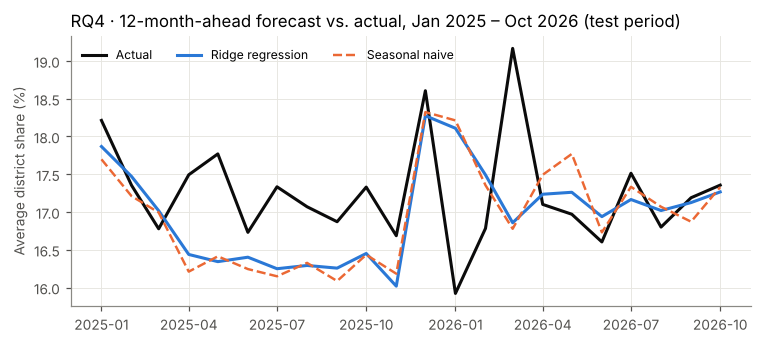

Ridge regression 12-month test MAE by borough (points):
 borough
Bronx            0.84
Brooklyn         0.80
Manhattan        0.92
Queens           0.99
Staten Island    1.50


In [13]:
# WHY the 12-month model for the chart: it answers RQ4 as written. Shares are averaged across districts
# (each district counts once) to show the overall fit; district-level errors are in the CSV.
best12 = rq4[rq4.horizon == "12 months ahead"].sort_values("test_MAE").iloc[0].model
col = f"12 months ahead | {best12}"
agg = preds.groupby("month")[["recycling_share_pct", "12 months ahead | Seasonal naive (same month last year)", col]].mean()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(agg.index, agg.recycling_share_pct, color=INK, lw=2, label="Actual")
ax.plot(agg.index, agg[col], color=BLUE, lw=2, label=best12)
ax.plot(agg.index, agg.iloc[:, 1], color=ORANGE, lw=1.6, ls="--", label="Seasonal naive")
ax.set_ylabel("Average district share (%)"); ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
ax.set_title("RQ4 · 12-month-ahead forecast vs. actual, Jan 2025 – Oct 2026 (test period)", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig8_rq4_forecast.png", dpi=200); plt.show()

err = preds.assign(abs_err=lambda d: (d.recycling_share_pct - d[col]).abs()).groupby("borough").abs_err.mean().round(2)
print(f"{best12} 12-month test MAE by borough (points):\n", err.to_string())

## 4b. Combining static traits with the time series (instructor feedback)
Scott's Milestone 1 feedback pointed out that our data comes in two kinds:
- **Static:** district traits that barely change (income, language, housing).
- **Dynamic:** the monthly recycling history.

Recurrent networks such as LSTMs struggle to mix the two, so he suggested an **ensemble** or a **Temporal Fusion Transformer (TFT)**, a model built to combine static traits with time series (Lim et al., 2021). This section tests both against the models above.

**A fair test.** Every model forecasts January–December 2025 using only data through December 2024, which is a true 12-month-ahead setup.
1. **Seasonal naive:** 2025 = the same month in 2024.
2. **Ridge regression:** the 12-month model from Section 4.
3. **Gradient boosting + static traits:** the Section 4 model plus the five district traits as extra columns.
4. **TFT:** static traits plus 24 months of history, forecasting 12 months at once. It is trained on 2005–2023 and stopped early on 2024, and its predictions are averaged over three training runs because one run can be noisy.
5. **Ensemble:** the average of models 2–4.

In Colab, run `!pip install pytorch-forecasting` once before this section. If it isn't installed, the TFT is skipped and the rest still runs.

In [14]:
# WHY a 2025-only window: every model below can be scored from the same forecast origin (Dec 2024).
win = preds[preds.month.dt.year == 2025][["month", "boro_cd", "borough", "recycling_share_pct"]].copy()
win["Seasonal naive"] = preds.loc[win.index, "12 months ahead | Seasonal naive (same month last year)"]
win["Ridge regression"] = preds.loc[win.index, "12 months ahead | Ridge regression"]

# Gradient boosting with the static traits added; tuned on 2024, refit on everything before 2025.
static = feat.set_index("boro_cd")[FEATURES]
add_static = lambda df: df.join(static, on="boro_cd")
cols_s = H["12 months ahead"] + FEATURES
tr_s, va_s, trva_s, te_s = (add_static(x) for x in (tr, va, trva, te))
cat_s = [c == "boro_code" for c in cols_s]
grid = [{"learning_rate": lr, "max_leaf_nodes": ml, "max_iter": 400} for lr in [0.03, 0.1] for ml in [15, 31]]
g_best = min(grid, key=lambda g: mae(va_s.recycling_share_pct, HistGradientBoostingRegressor(**g, categorical_features=cat_s, random_state=SEED)
                                    .fit(tr_s[cols_s], tr_s.recycling_share_pct).predict(va_s[cols_s])))
gbs = HistGradientBoostingRegressor(**g_best, categorical_features=cat_s, random_state=SEED).fit(trva_s[cols_s], trva_s.recycling_share_pct)
te_s["pred"] = gbs.predict(te_s[cols_s])
win["Gradient boosting + static traits"] = te_s.loc[win.index, "pred"]
print("GB + static settings chosen on 2024:", g_best)

GB + static settings chosen on 2024: {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'max_iter': 400}


In [15]:
# WHY a guarded import: the TFT needs PyTorch and pytorch-forecasting; without them the notebook should still finish.
try:
    import torch, lightning.pytorch as pl, logging
    from lightning.pytorch.callbacks import EarlyStopping
    from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
    from pytorch_forecasting.data import GroupNormalizer
    from pytorch_forecasting.metrics import QuantileLoss
    HAS_TFT = True
except ImportError:
    HAS_TFT = False
    print("pytorch-forecasting not installed: run !pip install pytorch-forecasting, then rerun this section.")

if HAS_TFT:
    logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)  # WHY: hides training chatter, keeps real errors
    d = monthly[["month", "boro_cd", "recycling_share_pct"]].merge(feat[["boro_cd", "borough"] + FEATURES], on="boro_cd")
    d["time_idx"] = (d.month.dt.year - 2005) * 12 + d.month.dt.month - 1   # WHY: the TFT needs a whole-number clock
    d["cal_month"] = d.month.dt.month.astype(str)                           # known ahead of time, so the model may use it
    d["group"] = d.boro_cd.astype(str)
    t_idx = lambda yr, mo: (yr - 2005) * 12 + mo - 1
    ENC, PRED = 24, 12   # WHY: two years of history in, one full year out, matching the RQ4 horizon

    train_ds = TimeSeriesDataSet(
        d[d.time_idx <= t_idx(2023, 12)], time_idx="time_idx", target="recycling_share_pct", group_ids=["group"],
        max_encoder_length=ENC, max_prediction_length=PRED,
        static_categoricals=["group", "borough"], static_reals=FEATURES,        # the static half
        time_varying_known_categoricals=["cal_month"], time_varying_known_reals=["time_idx"],
        time_varying_unknown_reals=["recycling_share_pct"],                    # the dynamic half
        target_normalizer=GroupNormalizer(groups=["group"]), add_relative_time_idx=True, add_target_scales=True)
    # WHY predict=True: each dataset holds one forecast per district, the 12 months after its last encoder month.
    val_ds = TimeSeriesDataSet.from_dataset(train_ds, d[d.time_idx <= t_idx(2024, 12)], predict=True, stop_randomization=True)
    test_ds = TimeSeriesDataSet.from_dataset(train_ds, d[d.time_idx <= t_idx(2025, 12)], predict=True, stop_randomization=True)

    def fit_tft(seed):
        '''Train one TFT with early stopping on 2024 and return the best checkpoint.

        WHY early stopping: training stops when the 2024 forecast stops improving, which limits overfitting.'''
        pl.seed_everything(seed, workers=True)
        model = TemporalFusionTransformer.from_dataset(train_ds, learning_rate=0.01, hidden_size=16, attention_head_size=2,
                                                       dropout=0.1, hidden_continuous_size=8, loss=QuantileLoss(),
                                                       log_interval=-1, reduce_on_plateau_patience=3)
        trainer = pl.Trainer(max_epochs=30, accelerator="cpu", gradient_clip_val=0.1, limit_train_batches=40,
                             enable_progress_bar=False, logger=False, enable_model_summary=False,
                             callbacks=[EarlyStopping(monitor="val_loss", patience=5)])
        trainer.fit(model, train_ds.to_dataloader(train=True, batch_size=64, num_workers=0),
                    val_ds.to_dataloader(train=False, batch_size=128, num_workers=0))
        return TemporalFusionTransformer.load_from_checkpoint(trainer.checkpoint_callback.best_model_path)

    runs = []
    for seed in [SEED, SEED + 1, SEED + 2]:
        best_tft = fit_tft(seed)
        out = best_tft.predict(test_ds.to_dataloader(train=False, batch_size=128, num_workers=0), return_index=True, mode="prediction")
        p = out.output.cpu().numpy()
        runs.append(pd.DataFrame([{"boro_cd": int(g), "month": pd.Timestamp(2025, h + 1, 1), f"run{seed}": p[i, h]}
                                  for i, g in enumerate(out.index["group"]) for h in range(PRED)]).set_index(["boro_cd", "month"]))
    tft_pred = pd.concat(runs, axis=1)
    run_mae = {c: mae(win.set_index(["boro_cd", "month"]).recycling_share_pct.reindex(tft_pred.index), tft_pred[c]) for c in tft_pred}
    print("TFT MAE by training run:", {k: round(v, 3) for k, v in run_mae.items()})
    win["TFT (static + history)"] = win.set_index(["boro_cd", "month"]).index.map(tft_pred.mean(axis=1))

TFT MAE by training run: {'run450': 0.96, 'run451': 1.086, 'run452': 1.136}


In [16]:
members = ["Ridge regression", "Gradient boosting + static traits"] + (["TFT (static + history)"] if HAS_TFT else [])
win["Ensemble (average)"] = win[members].mean(axis=1)   # WHY a plain average: no extra settings to overfit with 59 series

models_b = ["Seasonal naive", "Ridge regression", "Gradient boosting + static traits"] + \
           (["TFT (static + history)"] if HAS_TFT else []) + ["Ensemble (average)"]
rq4b = pd.DataFrame([{"model": mdl, "MAE_2025": mae(win.recycling_share_pct, win[mdl]),
                      "RMSE_2025": rmse(win.recycling_share_pct, win[mdl])} for mdl in models_b])
rq4b["vs_seasonal_naive_pct"] = (1 - rq4b.MAE_2025 / rq4b.MAE_2025.iloc[0]) * 100
print(f"12-month-ahead forecasts of 2025 from a Dec 2024 origin ({len(win)} district-months):")
print(rq4b.round(3).to_string(index=False))
rq4b.to_csv("model_results/rq4b_static_ensemble_tft.csv", index=False)
win.to_csv("model_results/rq4b_2025_predictions.csv", index=False)

12-month-ahead forecasts of 2025 from a Dec 2024 origin (708 district-months):
                            model  MAE_2025  RMSE_2025  vs_seasonal_naive_pct
                   Seasonal naive     0.911      1.191                  0.000
                 Ridge regression     0.903      1.158                  0.840
Gradient boosting + static traits     0.873      1.138                  4.180
           TFT (static + history)     1.005      1.290                -10.358
               Ensemble (average)     0.892      1.155                  2.026


In [17]:
# WHY show the TFT's own variable weights: they say whether the static traits actually moved its forecasts.
if HAS_TFT:
    raw = best_tft.predict(test_ds.to_dataloader(train=False, batch_size=128, num_workers=0), mode="raw", return_x=True)
    interp = best_tft.interpret_output(raw.output, reduction="sum")
    w_static = pd.Series(interp["static_variables"].numpy(), index=best_tft.static_variables)
    w_enc = pd.Series(interp["encoder_variables"].numpy(), index=best_tft.encoder_variables)
    print("TFT static variable weights (share of total):\n", (w_static / w_static.sum()).sort_values(ascending=False).round(3).to_string())
    print("\nTFT history (encoder) variable weights:\n", (w_enc / w_enc.sum()).sort_values(ascending=False).round(3).to_string())

TFT static variable weights (share of total):
 recycling_share_pct_center    0.187
log_income                    0.186
group                         0.172
nycha_share                   0.107
recycling_share_pct_scale     0.101
rent_stab_share               0.095
permits_per_1k                0.082
lep_pct                       0.044
borough                       0.027

TFT history (encoder) variable weights:
 recycling_share_pct    0.611
cal_month              0.165
relative_time_idx      0.139
time_idx               0.085


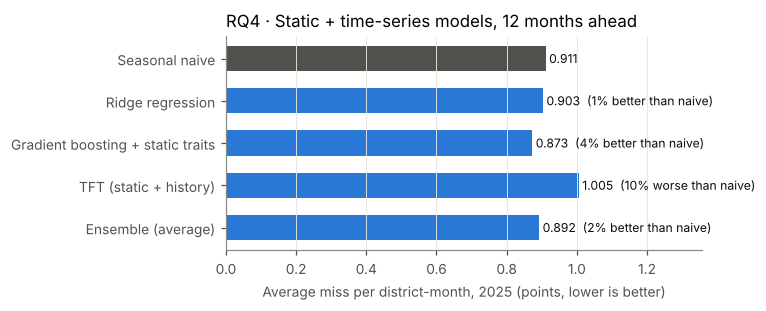

In [18]:
r = rq4b.iloc[::-1]
fig, ax = plt.subplots(figsize=(6.8, 2.9))
ax.barh(r.model, r.MAE_2025, color=[MUTED if m == "Seasonal naive" else BLUE for m in r.model], height=0.6)
for i, (v, pct) in enumerate(zip(r.MAE_2025, r.vs_seasonal_naive_pct)):
    ax.text(v + 0.01, i, f"{v:.3f}" + ("" if abs(pct) < 0.05 else f"  ({abs(pct):.0f}% {'better' if pct > 0 else 'worse'} than naive)"), va="center", fontsize=8, color=INK)
ax.set_xlim(0, r.MAE_2025.max() * 1.35); ax.grid(axis="y", visible=False)
ax.set_xlabel("Average miss per district-month, 2025 (points, lower is better)")
ax.set_title("RQ4 · Static + time-series models, 12 months ahead", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig10_rq4_static_ensemble_tft.png", dpi=200); plt.show()

### What this section shows
- **Static traits help a little.** Adding the five district traits to gradient boosting gave the best 12-month forecast of 2025: it missed by 0.87 points on average, 4% better than seasonal naive (0.91) and better than ridge without traits (0.90).
- **The TFT did not beat the baseline here.** Averaged over three runs it missed by 1.01 points, 10% worse than seasonal naive. Its runs also disagreed (0.96 to 1.14), a sign it is too flexible for 59 short series of about 20 years each. TFTs shine with many more series or richer known-future inputs (Lim et al., 2021), and this problem has neither.
- **The TFT still agrees with RQ2.** Among the static inputs it weighted income most, alongside each district's own typical level. Language access got the least weight.
- **The ensemble lands in the middle** (0.89, 2% better than naive). Averaging smoothed the TFT's misses but couldn't beat the best single model.
- **Why the ceiling is low:** a year ahead, most of the change is citywide (the spring 2025 jump in Section 4), and no district trait predicts that. Static traits explain *which* districts are high or low (RQ2) far better than *how they will change* (RQ4).

**Bottom line for the report:** we tested the recommended approach. The best year-ahead forecast is a gradient boosting ensemble of history plus static traits, a modest gain over seasonal naive, and the TFT is reported as tested but not selected.

## 5. Results summary
**RQ2 · Associations.** Income does almost all the work. An income-only model misses a district's 2025 share by 2.43 points on average in cross-validation, against 4.26 for guessing the average (43% better, R² ≈ 0.59). Adding language, housing and permits makes predictions slightly *worse* (2.55–2.71), which is the small-sample overfitting the readings warn about. In the full regression (R² = 0.68), one standard deviation more income goes with about 4.8 more points of recycling share (95% CI 3.7 to 6.0). The other four traits are all uncertain once income is held constant. Their negative correlations in the EDA mostly reflected income. This holds with Furman income, without Manhattan 1, and in the random forest's importance ranking.

**RQ2 · Who falls short of their income.** Brooklyn 8 (−10.3 points), Manhattan 10 (−6.5), Bronx 2 (−5.9), Brooklyn 4 (−4.5) and Brooklyn 11 (−4.2) recycle well below what their income predicts. Something beyond income holds them back, which makes them the strongest outreach candidates. Manhattan 5 (−5.7) is mostly commercial Midtown, so treat it with caution. Queens 1 and 11, Bronx 7 and 8, and Brooklyn 6 beat their prediction and may hold lessons.

**RQ3 · High-risk flagging.** Last year's list finds 14 of the 15 lowest districts (93%). Trait-only models find 11 (logistic, 73%) and 10 (random forest, 67%), about three times better than random but well short of history. Recommendation: flag districts with last year's ranking and use the traits to explain *why*. The two lists disagree on Bronx 5 and 7 and Brooklyn 2 and 13 (traits say risky, history says fine) and Manhattan 10 and Brooklyn 8, 11 and 12 (low despite their traits). The last group matches the below-income list.

**RQ4 · Forecasting.** One month ahead, ridge and gradient boosting cut the seasonal-naive error by about 20% (MAE 0.75 vs. 0.95 points). Twelve months ahead, which is the RQ4 question, gains are small. Following Scott's feedback, Section 4b combined static traits with the time series. Gradient boosting with the traits was best (4% better than seasonal naive on 2025), the ensemble was 2% better, and the Temporal Fusion Transformer was 10% worse and unstable across runs. From April 2025, actual shares run about a point above every forecast, a citywide shift that no district trait can anticipate. It may line up with the curbside composting rules; worth checking before the report claims it.

**Scope (per Scott's advice to narrow if needed):** RQ1 and RQ2 carry the story. RQ3 works best reframed as "explain why," since last year's list already flags the districts, and RQ4 can be reported as a tested, modest result rather than expanded further.

**For the report:** lead with income and the below-income list, reword RQ3 from "predict" to "explain," and report the forecast honestly: useful for next month, close to seasonal naive for next year.

## References
Provost, F., & Fawcett, T. (2013). *Data science for business: What you need to know about data mining and data-analytic thinking*. O'Reilly Media.

Stephens-Davidowitz, S. (2017). *Everybody lies: Big data, new data, and what the internet can tell us about who we really are*. Dey Street Books.

Lim, B., Arık, S. Ö., Loeff, N., & Pfister, T. (2021). Temporal fusion transformers for interpretable multi-horizon time series forecasting. *International Journal of Forecasting, 37*(4), 1748–1764. https://doi.org/10.1016/j.ijforecast.2021.03.012